In [ ]:
!pip -q install pyspark kagglehub pyarrow requests

In [ ]:
import os, time, glob, textwrap, requests
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.backends.backend_pdf import PdfPages
from concurrent.futures import ThreadPoolExecutor, as_completed
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.appName("SolarPoster").master("local[*]")
         .config("spark.sql.ansi.enabled", "false")
         .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.driver.memory", "6g")
         .getOrCreate())

In [ ]:
import kagglehub
path = kagglehub.dataset_download("anikannal/solar-power-generation-data")
print(os.listdir(path))

def load(name):
    d = spark.read.csv(f"{path}/{name}", header=True, inferSchema=True)
    return d.withColumn("DATE_TIME", F.col("DATE_TIME").cast("string"))

gen = load("Plant_1_Generation_Data.csv").unionByName(load("Plant_2_Generation_Data.csv"))
wx  = load("Plant_1_Weather_Sensor_Data.csv").unionByName(load("Plant_2_Weather_Sensor_Data.csv"))

def parse_ts(c):
    return F.coalesce(F.to_timestamp(c, "dd-MM-yyyy HH:mm"), F.to_timestamp(c, "yyyy-MM-dd HH:mm:ss"))

gen = gen.withColumn("DATE_TIME", parse_ts(F.col("DATE_TIME")))
wx  = wx.withColumn("DATE_TIME", parse_ts(F.col("DATE_TIME")))
print("Generation rows:", gen.count(), "| Weather rows:", wx.count())

Using Colab cache for faster access to the 'solar-power-generation-data' dataset.
['Plant_2_Generation_Data.csv', 'Plant_2_Weather_Sensor_Data.csv', 'Plant_1_Weather_Sensor_Data.csv', 'Plant_1_Generation_Data.csv']
Generation rows: 136476 | Weather rows: 6441


In [ ]:
data = (gen.join(wx.select("PLANT_ID", "DATE_TIME", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"),
                 ["PLANT_ID", "DATE_TIME"]).dropna())
ids = sorted(r[0] for r in data.select("PLANT_ID").distinct().collect())
data = (data.withColumn("hour", F.hour("DATE_TIME"))
            .withColumn("minute", F.minute("DATE_TIME"))
            .withColumn("date", F.to_date("DATE_TIME"))
            .withColumn("plant", F.when(F.col("PLANT_ID") == ids[1], 1).otherwise(0))
            .withColumn("energy_kwh", F.col("AC_POWER") * 0.25))
data = data.cache()
n_rows_A = data.count()
print("Inverter-level rows used for modelling:", f"{n_rows_A:,}")

Inverter-level rows used for modelling: 136,472


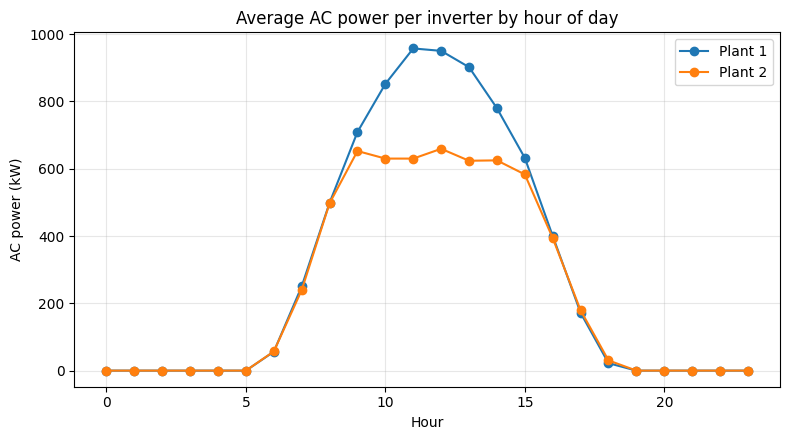

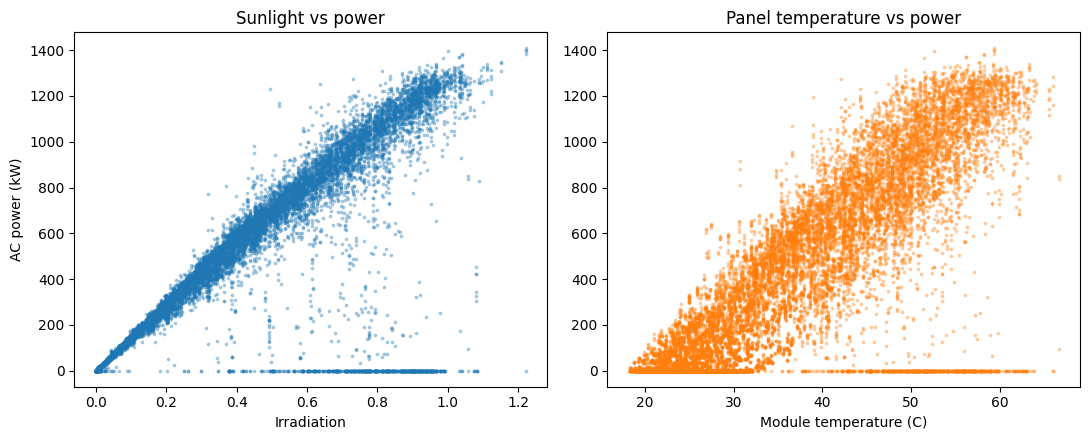

In [ ]:
hourly_A = (data.groupBy("plant", "hour").agg(F.avg("AC_POWER").alias("avg_ac")).orderBy("hour").toPandas())
pv = hourly_A.pivot(index="hour", columns="plant", values="avg_ac"); pv.columns = ["Plant 1", "Plant 2"]
ax = pv.plot(figsize=(8, 4.5), marker="o")
ax.set_title("Average AC power per inverter by hour of day"); ax.set_xlabel("Hour"); ax.set_ylabel("AC power (kW)")
ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig("chart1_hourly_power.png", dpi=200); plt.show()

sm = data.select("IRRADIATION", "MODULE_TEMPERATURE", "AC_POWER").sample(0.2, seed=1).toPandas()
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].scatter(sm["IRRADIATION"], sm["AC_POWER"], s=3, alpha=0.3)
axs[0].set_xlabel("Irradiation"); axs[0].set_ylabel("AC power (kW)"); axs[0].set_title("Sunlight vs power")
axs[1].scatter(sm["MODULE_TEMPERATURE"], sm["AC_POWER"], s=3, alpha=0.3, color="tab:orange")
axs[1].set_xlabel("Module temperature (C)"); axs[1].set_title("Panel temperature vs power")
plt.tight_layout(); plt.savefig("chart2_weather_vs_power.png", dpi=200); plt.show()

In [ ]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

feature_cols = ["hour", "minute", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION", "plant"]
ml_A = (VectorAssembler(inputCols=feature_cols, outputCol="features").transform(data)
        .select("DATE_TIME", "date", "plant", "features", F.col("AC_POWER").alias("label")))

dates = sorted(r[0] for r in ml_A.select("date").distinct().collect())
cut_A = dates[int(len(dates) * 0.8)]            # train on first 80% of days, test on the last days
train_A = ml_A.filter(F.col("date") < cut_A).coalesce(4).cache()
test_A  = ml_A.filter(F.col("date") >= cut_A).coalesce(4).cache()
n_train_A, n_test_A = train_A.count(), test_A.count()
print("Split date:", cut_A, "| train:", n_train_A, "| test:", n_test_A)

models = {
    "Linear Regression": LinearRegression(featuresCol="features", labelCol="label"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50, maxDepth=6, seed=42),
    "Gradient Boosted Trees": GBTRegressor(featuresCol="features", labelCol="label", maxIter=30, maxDepth=4, seed=42),
}
rows, fitted_A, preds_A = [], {}, {}
for name, est in models.items():
    t0 = time.time()
    m = est.fit(train_A); p = m.transform(test_A)
    fitted_A[name], preds_A[name] = m, p
    sc = {k: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=k).evaluate(p)
          for k in ["mae", "rmse", "r2"]}
    rows.append({"Model": name, "MAE": sc["mae"], "RMSE": sc["rmse"], "R2": sc["r2"]})
    print(f"{name} done in {time.time()-t0:.0f} s")

results_A = pd.DataFrame(rows).round(3)
best_A = results_A.sort_values("R2", ascending=False).iloc[0]["Model"]
print(results_A.to_string(index=False)); print("Best model:", best_A)

Split date: 2020-06-11 | train: 106948 | test: 29524
Linear Regression done in 5 s
Random Forest done in 18 s
Gradient Boosted Trees done in 33 s
                 Model    MAE    RMSE    R2
     Linear Regression 79.607 137.077 0.821
         Random Forest 44.048 119.014 0.865
Gradient Boosted Trees 41.255 115.554 0.873
Best model: Gradient Boosted Trees


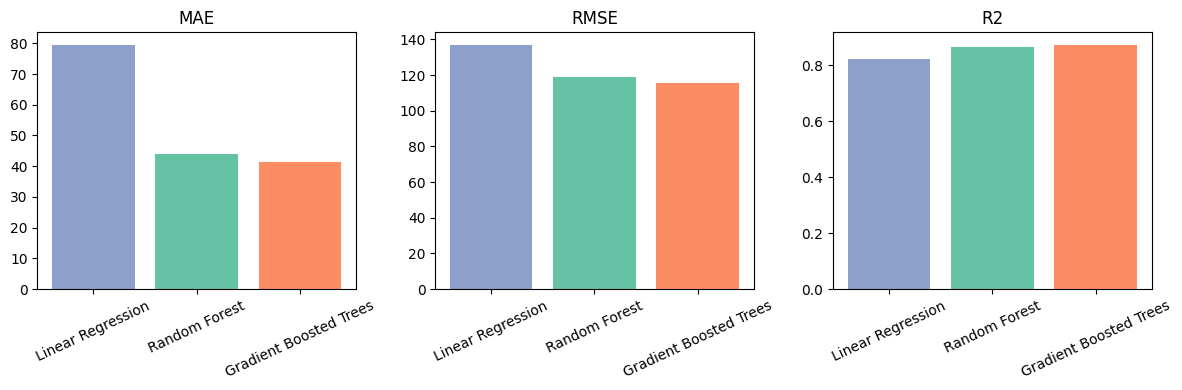

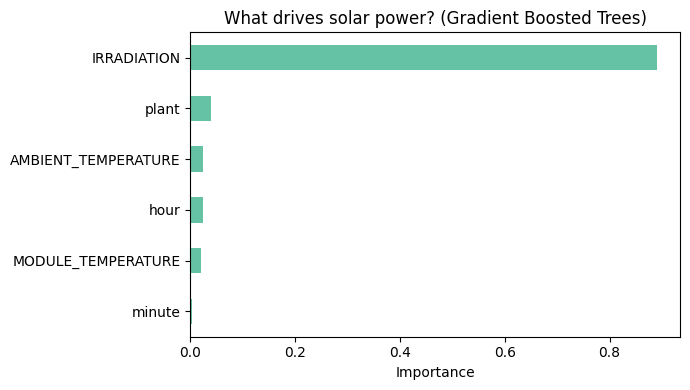

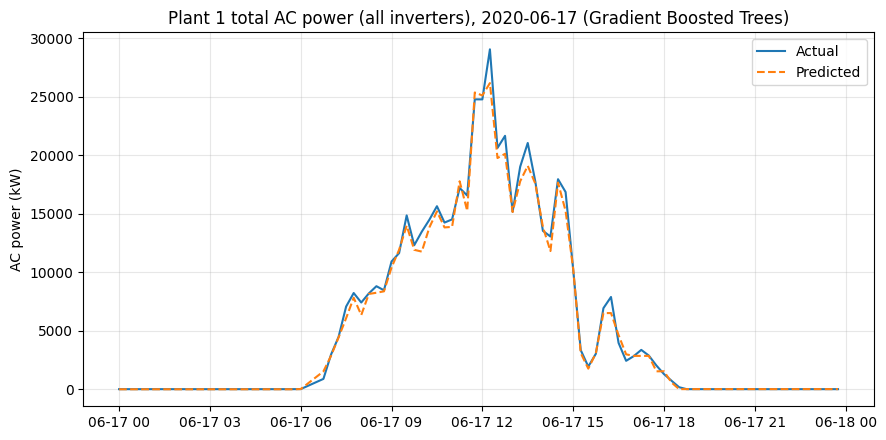

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, k in zip(axs, ["MAE", "RMSE", "R2"]):
    ax.bar(results_A["Model"], results_A[k], color=["#8da0cb", "#66c2a5", "#fc8d62"])
    ax.set_title(k); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig("chart3_model_scores.png", dpi=200); plt.show()

tree_name = best_A if best_A != "Linear Regression" else "Random Forest"
imp = pd.Series(fitted_A[tree_name].featureImportances.toArray(), index=feature_cols).sort_values()
ax = imp.plot(kind="barh", figsize=(7, 4), color="#66c2a5")
ax.set_title(f"What drives solar power? ({tree_name})"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.savefig("chart4_feature_importance.png", dpi=200); plt.show()

p = preds_A[best_A]
last_day = p.agg(F.max("date")).collect()[0][0]
day = (p.filter((F.col("date") == last_day) & (F.col("plant") == 0))
        .groupBy("DATE_TIME").agg(F.sum("label").alias("actual"), F.sum("prediction").alias("predicted"))
        .orderBy("DATE_TIME").toPandas())
plt.figure(figsize=(9, 4.5))
plt.plot(day["DATE_TIME"], day["actual"], label="Actual")
plt.plot(day["DATE_TIME"], day["predicted"], label="Predicted", linestyle="--")
plt.title(f"Plant 1 total AC power (all inverters), {last_day} ({best_A})")
plt.ylabel("AC power (kW)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("chart5_actual_vs_predicted.png", dpi=200); plt.show()

Avg % of daily energy made 10:00-14:59:
 plant
0    62.0
1    54.4
Name: midday_share_pct, dtype: float64


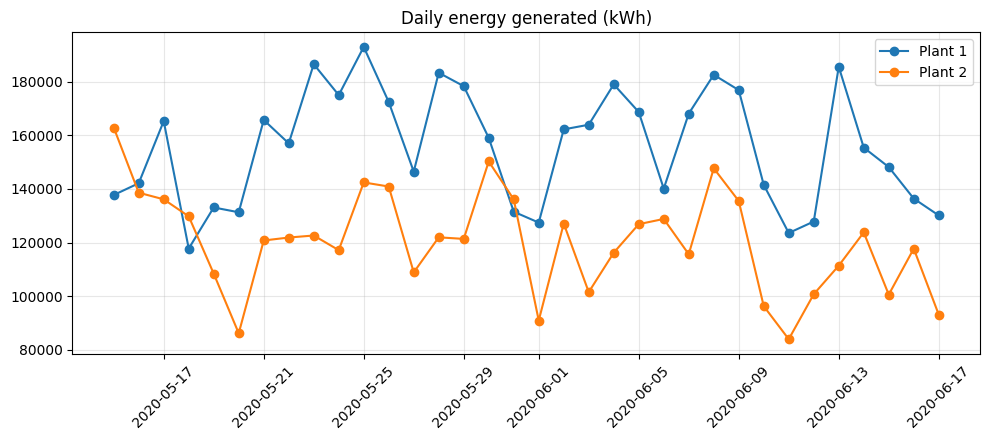


Low-output days (below 70% of the plant's median day):
 plant       date  daily_kwh
     1 2020-06-11    83962.0


In [ ]:
daily = (data.groupBy("plant", "date")
         .agg(F.sum("energy_kwh").alias("daily_kwh"),
              F.sum(F.when(F.col("hour").between(10, 14), F.col("energy_kwh")).otherwise(0)).alias("midday_kwh"))
         .withColumn("midday_share_pct", F.round(F.col("midday_kwh") / F.col("daily_kwh") * 100, 1))
         .orderBy("plant", "date").toPandas())
midday_A = daily.groupby("plant")["midday_share_pct"].mean().round(1)
print("Avg % of daily energy made 10:00-14:59:\n", midday_A)

plt.figure(figsize=(10, 4.5))
for pl, label in [(0, "Plant 1"), (1, "Plant 2")]:
    d = daily[daily["plant"] == pl]; plt.plot(d["date"], d["daily_kwh"], marker="o", label=label)
plt.title("Daily energy generated (kWh)"); plt.xticks(rotation=45); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("chart6_daily_energy.png", dpi=200); plt.show()

daily["median_kwh"] = daily.groupby("plant")["daily_kwh"].transform("median")
low = daily[daily["daily_kwh"] < 0.7 * daily["median_kwh"]]
print("\nLow-output days (below 70% of the plant's median day):")
print(low[["plant", "date", "daily_kwh"]].round(0).to_string(index=False))

In [ ]:
import os, time, warnings, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figs", exist_ok=True)
TEAL, AMBER, RED, GREY = "#1f8a70", "#f5a300", "#d9573b", "#8da0cb"
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":300, "axes.grid":True, "grid.alpha":0.3,
                     "font.size":12, "axes.titleweight":"bold"})
def save(name): plt.tight_layout(); plt.savefig(f"figs/{name}.png", bbox_inches="tight"); plt.show()

Power vs sunlight (daytime): r = 0.718, R2 = 0.515
                           MAE_kW            RMSE_kW              R2         \
                             mean      std      mean      std   mean    std   
model                                                                         
Persistence (power now)  3958.746  277.588  5088.652  386.694  0.519  0.083   
Linear Regression        3367.701  236.974  4420.619  441.218  0.635  0.079   
Gradient Boosted Trees   2493.766  276.541  3587.462  438.683  0.759  0.061   

                        nMAE_pct         
                            mean    std  
model                                    
Persistence (power now)   37.411  3.789  
Linear Regression         31.820  3.165  
Gradient Boosted Trees    23.577  3.155  


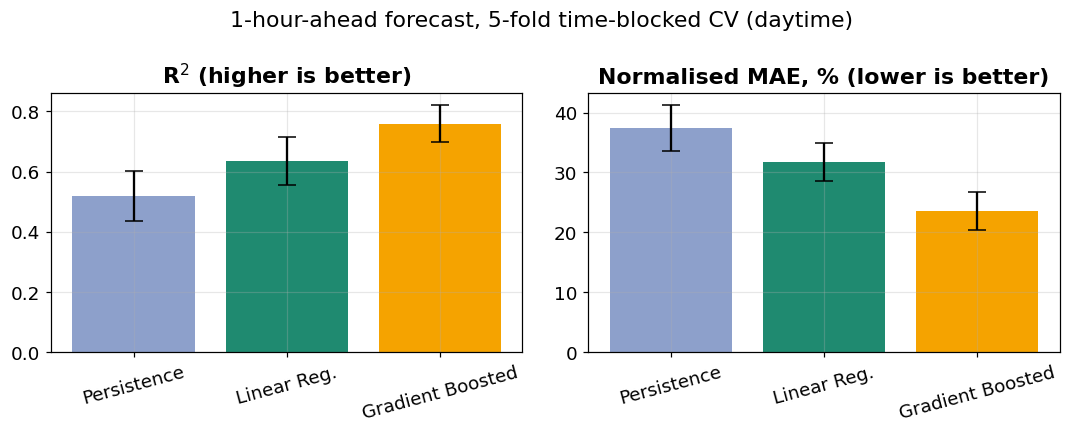

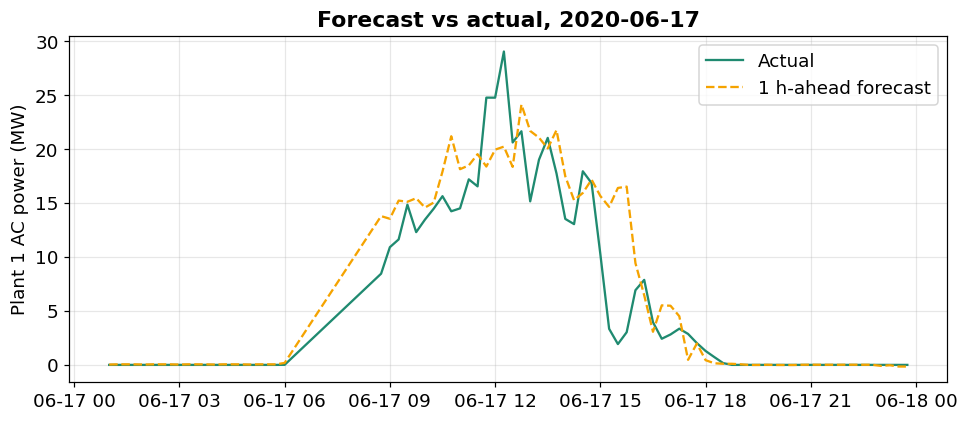

In [ ]:
from pyspark.sql import Window, functions as F
from pyspark.sql.types import IntegerType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor, LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# 1) How linear is power vs sunlight? (supports the Part C sizing formula)
d = data.filter(F.col("IRRADIATION") > 0.05).select("IRRADIATION","AC_POWER").sample(0.3, seed=1).toPandas()
r = d.corr().iloc[0,1]; print(f"Power vs sunlight (daytime): r = {r:.3f}, R2 = {r*r:.3f}")

# 2) plant-level series, predict power 1 hour (4 x 15 min) ahead
ts = (data.groupBy("plant","DATE_TIME")
      .agg(F.sum("AC_POWER").alias("power"), F.avg("IRRADIATION").alias("irr"),
           F.avg("MODULE_TEMPERATURE").alias("mod_t"), F.avg("AMBIENT_TEMPERATURE").alias("amb_t"))
      .withColumn("date",F.to_date("DATE_TIME")).withColumn("hour",F.hour("DATE_TIME"))
      .withColumn("minute",F.minute("DATE_TIME")))
w = Window.partitionBy("plant").orderBy("DATE_TIME"); H = 4
ts = (ts.withColumn("label",F.lead("power",H).over(w)).withColumn("t_next",F.lead("DATE_TIME",H).over(w))
        .withColumn("t_prev",F.lag("DATE_TIME",H).over(w))
        .withColumn("power_l1",F.lag("power",1).over(w)).withColumn("power_l4",F.lag("power",H).over(w))
        .withColumn("irr_l1",F.lag("irr",1).over(w)).withColumn("irr_l4",F.lag("irr",H).over(w)).dropna()
        .filter((F.unix_timestamp("t_next")-F.unix_timestamp("DATE_TIME")==3600) &
                (F.unix_timestamp("DATE_TIME")-F.unix_timestamp("t_prev")==3600)))
dates = sorted(r_[0] for r_ in ts.select("date").distinct().collect()); K = 5
fold_of = {dt:i*K//len(dates) for i,dt in enumerate(dates)}
ts = ts.withColumn("fold", F.udf(lambda x: fold_of[x], IntegerType())("date"))
feat = ["hour","minute","plant","irr","mod_t","amb_t","power","power_l1","power_l4","irr_l1","irr_l4"]
ml = (VectorAssembler(inputCols=feat, outputCol="features").transform(ts)
      .select("fold","hour","plant","DATE_TIME","date","power","label","features").cache())

def score(df, pred):                      # daytime only: night zeros would inflate R2
    dd = df.filter(F.col("hour").between(6,18)); m = dd.agg(F.avg("label")).first()[0]
    ev = lambda k: RegressionEvaluator(labelCol="label",predictionCol=pred,metricName=k).evaluate(dd)
    return ev("mae"), ev("rmse"), ev("r2"), 100*ev("mae")/m

rows, last_pred = [], None
for k in range(K):
    tr, te = ml.filter(F.col("fold")!=k), ml.filter(F.col("fold")==k)
    rows.append(("Persistence (power now)",k,*score(te,"power")))
    lr = LinearRegression(featuresCol="features").fit(tr);  rows.append(("Linear Regression",k,*score(lr.transform(te),"prediction")))
    gb = GBTRegressor(featuresCol="features",maxIter=60,maxDepth=5,seed=1).fit(tr); pr = gb.transform(te)
    rows.append(("Gradient Boosted Trees",k,*score(pr,"prediction")))
    if k == K-1: last_pred = pr
cv = pd.DataFrame(rows, columns=["model","fold","MAE_kW","RMSE_kW","R2","nMAE_pct"])
order = ["Persistence (power now)","Linear Regression","Gradient Boosted Trees"]
summ = cv.groupby("model")[["MAE_kW","RMSE_kW","R2","nMAE_pct"]].agg(["mean","std"]).loc[order].round(3)
print(summ); summ.to_csv("figs/cv_summary.csv")

# Figure A1: model comparison with error bars
fig, ax = plt.subplots(1,2, figsize=(10,4))
for a, col, ttl in zip(ax, ["R2","nMAE_pct"], ["R$^2$ (higher is better)","Normalised MAE, % (lower is better)"]):
    m = cv.groupby("model")[col].mean().loc[order]; s = cv.groupby("model")[col].std().loc[order]
    a.bar(range(3), m, yerr=s, capsize=6, color=[GREY,TEAL,AMBER]); a.set_xticks(range(3))
    a.set_xticklabels(["Persistence","Linear Reg.","Gradient Boosted"], rotation=15); a.set_title(ttl)
fig.suptitle("1-hour-ahead forecast, 5-fold time-blocked CV (daytime)"); save("A1_model_comparison")

# Figure A2: actual vs forecast, last test day, plant 0
pdf = (last_pred.filter(F.col("plant")==0).filter(F.col("date")==dates[-1])
       .select("DATE_TIME","label","prediction").orderBy("DATE_TIME").toPandas())
pdf["target_time"] = pd.to_datetime(pdf["DATE_TIME"]) + pd.Timedelta(hours=1)
plt.figure(figsize=(9,4)); plt.plot(pdf.target_time, pdf.label/1000, color=TEAL, label="Actual")
plt.plot(pdf.target_time, pdf.prediction/1000, "--", color=AMBER, label="1 h-ahead forecast")
plt.ylabel("Plant 1 AC power (MW)"); plt.title(f"Forecast vs actual, {dates[-1]}"); plt.legend(); save("A2_actual_vs_forecast")